# Lending Club — First Look at the Problem and the Data

A step-by-step walkthrough of how I understood the problem (notebook 01) and the data
(notebook 02) before building any model. Each step is: **run a simple command → look at
the output → write down what it tells me**.

**Dataset:** Kaggle `wordsforthewise/lending-club`, file `accepted_2007_to_2018Q4.csv.gz`.

## Part 1 — Understanding the problem (notebook 01)

Before opening the data I wrote down four answers:

| Question | My answer |
|---|---|
| What do we predict? | Whether a loan ends **Charged Off / Default (1)** or **Fully Paid (0)** |
| When do we predict it? | At the moment of **application**, before the money is lent |
| What does a mistake cost? | Missing a default (FN) loses the principal; rejecting a good borrower (FP) loses only the interest. So **FN is much more expensive** (we assume FN:FP = 4:1) |
| What already exists? | Lending Club already gives every loan a **grade A–G / sub-grade A1–G5**. Our model must beat that |

The second answer is the most important one: **only information known at application time may be used.**

## Part 2 — Understanding the data (notebook 02)

### Step 0 — Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)

# Find the data file: works for .csv or .csv.gz, from the repo root or from notebooks/
found = []
for folder in [Path("data/raw"), Path("../data/raw")]:
    if folder.exists():
        found += sorted(folder.rglob("accepted_2007_to_2018*.csv*"))

print("Current folder:", Path.cwd())
print("Files found:", found)
DATA_PATH = found[0]
print("Using:", DATA_PATH)

Current folder: /home/orlab/Lending-Club/notebooks
Files found: [PosixPath('../data/raw/accepted_2007_to_2018Q4.csv')]
Using: ../data/raw/accepted_2007_to_2018Q4.csv


In [ ]:
df = pd.read_csv(DATA_PATH, nrows=5)  
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,...,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,leadman,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,190xx,PA,5.91,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,small_business,Business,577xx,SD,16.06,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,truck driver,10+ years,MORTGAGE,63000.0,Not Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,home_improvement,NaN,605xx,IL,10.78,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,Information Systems Officer,10+ years,MORTGAGE,110000.0,Source Verified,Dec-2015,Current,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,debt_consolidation,Debt consolidation,076xx,NJ,17.06,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,Contract Specialist,3 years,MORTGAGE,104433.0,Source Verified,Dec-2015,Fully Paid,n,https://lendingclub.com/browse/loanDetail.acti...,NaN,major_purchase,Major purchase,174xx,PA,25.37,...,NaN,NaN,N,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


### Step 1 — How many columns does the file have?

Reading only the header (`nrows=0`) is instant, even for a 1.6 GB file.

In [9]:
all_columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
print("Number of columns:", len(all_columns))
print(all_columns[:20], "...")

Number of columns: 151
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc'] ...


**Observation:** the file has **151 columns**. Many of them describe what happened *after*
the loan was given (payments, recoveries, settlements). We cannot use those, because we
predict at application time. So I load only the columns I need.

### Step 2 — Load the columns we need

In [ ]:
use_cols = [
    # outcome
    "loan_status",
    # loan request
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade", "purpose",
    # applicant
    "emp_length", "home_ownership", "annual_inc", "verification_status", "addr_state",
    # credit bureau
    "dti", "delinq_2yrs", "earliest_cr_line", "fico_range_low", "fico_range_high",
    "inq_last_6mths", "mths_since_last_delinq", "open_acc", "pub_rec", "revol_bal",
    "revol_util", "total_acc", "mort_acc", "pub_rec_bankruptcies",
    # time
    "issue_d",
    # loaded ONLY to demonstrate leakage in Step 5 -- never used as a feature
    "recoveries",
    # loaded ONLY to check the bureau columns in Step 13
    "bc_util", "il_util",
]
df = pd.read_csv(DATA_PATH, usecols=use_cols, low_memory=False)
print("Shape:", df.shape)
df.head()

Shape: (2260701, 31)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,open_acc,pub_rec,revol_bal,revol_util,total_acc,recoveries,il_util,bc_util,mort_acc,pub_rec_bankruptcies
0,3600.0,36 months,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,Dec-2015,Fully Paid,debt_consolidation,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,30.0,7.0,0.0,2765.0,29.7,13.0,0.0,36.0,37.2,1.0,0.0
1,24700.0,36 months,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,Dec-2015,Fully Paid,small_business,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,6.0,22.0,0.0,21470.0,19.2,38.0,0.0,73.0,27.1,4.0,0.0
2,20000.0,60 months,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,Dec-2015,Fully Paid,home_improvement,IL,10.78,0.0,Aug-2000,695.0,699.0,0.0,NaN,6.0,0.0,7869.0,56.2,18.0,0.0,73.0,55.9,5.0,0.0
3,35000.0,60 months,14.85,829.90,C,C5,10+ years,MORTGAGE,110000.0,Source Verified,Dec-2015,Current,debt_consolidation,NJ,17.06,0.0,Sep-2008,785.0,789.0,0.0,NaN,13.0,0.0,7802.0,11.6,17.0,0.0,70.0,12.1,1.0,0.0
4,10400.0,60 months,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,Source Verified,Dec-2015,Fully Paid,major_purchase,PA,25.37,1.0,Jun-1998,695.0,699.0,3.0,12.0,12.0,0.0,21929.0,64.5,35.0,0.0,84.0,77.5,6.0,0.0


### Step 3 — What type is each column?

In [ ]:
df.dtypes

loan_amnt                 float64
term                          str
int_rate                  float64
installment               float64
grade                         str
sub_grade                     str
emp_length                    str
home_ownership                str
annual_inc                float64
verification_status           str
issue_d                       str
loan_status                   str
purpose                       str
addr_state                    str
dti                       float64
delinq_2yrs               float64
earliest_cr_line              str
fico_range_low            float64
fico_range_high           float64
inq_last_6mths            float64
mths_since_last_delinq    float64
open_acc                  float64
pub_rec                   float64
revol_bal                 float64
revol_util                float64
total_acc                 float64
recoveries                float64
il_util                   float64
bc_util                   float64
mort_acc      

**Observation:** `term`, `emp_length`, `issue_d` and `earliest_cr_line` are stored as
**text** (`str` / `object`), not numbers or dates — for example `term` looks like
`" 36 months"` and `issue_d` looks like `"Dec-2015"`. They must be converted before we can
plot or model them. (`int_rate` is already a number in this version of the file; other
versions store it as `"13.99%"`, so the code in Step 6 handles both.)

In [ ]:
df[["int_rate", "term", "emp_length", "issue_d", "earliest_cr_line"]].head()

,int_rate,term,emp_length,issue_d,earliest_cr_line
0,13.99,36 months,10+ years,Dec-2015,Aug-2003
1,11.99,36 months,10+ years,Dec-2015,Dec-1999
2,10.78,60 months,10+ years,Dec-2015,Aug-2000
3,14.85,60 months,10+ years,Dec-2015,Sep-2008
4,22.45,60 months,3 years,Dec-2015,Jun-1998


### Step 4 — The target variable

What values does `loan_status` take?

In [ ]:
df["loan_status"].value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

**Observation:** there are more than two values.
- `Fully Paid` → the loan was repaid → **0**
- `Charged Off`, `Default` → the borrower stopped paying (about 4–5 months late) → **1**
- `Current`, `Late`, `In Grace Period` → **the loan is not finished yet**, so we do not
  know the answer. These rows must be removed.
- `Does not meet the credit policy...` → old loans under a different policy; removed too.

In [ ]:
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y", errors="coerce")
df = df.dropna(subset=["issue_d"])

finished = df["loan_status"].isin(["Fully Paid", "Charged Off", "Default"])

# Before removing them: how many loans are finished, by issue year?
share_finished = finished.groupby(df["issue_d"].dt.year).mean()
print("Share of loans with a final outcome, by issue year:")
print(share_finished.round(3))

Share of loans with a final outcome, by issue year:
issue_d
2007    0.416
2008    0.653
2009    0.893
2010    0.920
2011    1.000
2012    1.000
2013    1.000
2014    0.947
2015    0.892
2016    0.675
2017    0.382
2018    0.114
Name: loan_status, dtype: float64


**Observation:** almost all loans from 2012–2014 are finished, but only a small share of
2018 loans are. A loan issued in 2018 is only "finished" if it ended **early** (an early
default or an early repayment). So the recent years are not a normal sample. This is
called **right-censoring**, and we must keep it in mind when we read results for 2016–2018.

Rows kept: 1345350
Default rate: 0.1996


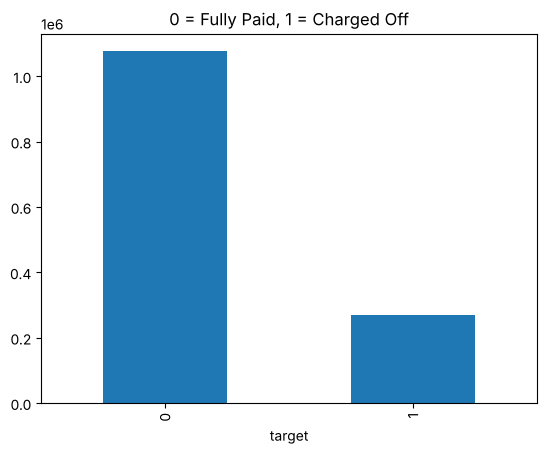

In [ ]:
df = df[finished].copy()
df["target"] = df["loan_status"].isin(["Charged Off", "Default"]).astype(int)

print("Rows kept:", len(df))
print("Default rate:", round(df["target"].mean(), 4))

df["target"].value_counts().plot(kind="bar", title="0 = Fully Paid, 1 = Charged Off")
plt.show()

**Observation:** about **1 in 5** loans defaults. The classes are imbalanced, so
**accuracy is a bad metric**: a model that always says "no default" would already be 80%
accurate and completely useless.

### Step 5 — Why some columns are forbidden (leakage)

`recoveries` is money collected *after* a loan was charged off. Let me check it by target.

In [ ]:
df.groupby("target")["recoveries"].describe()

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1076751.0,0.000000,0.000000,0.0,0.0,0.0,0.00,0.00
1,268599.0,1209.276812,1847.224639,0.0,0.0,592.0,1723.59,39859.55


**Observation:** `recoveries` is (almost) always 0 for repaid loans and often positive for
defaulted loans. It only exists **because** the loan defaulted, so it "contains the answer".
A model using it would look almost perfect (AUC near 0.99) but would be useless in real
life. Columns like this (payments, recoveries, settlements, the FICO score pulled *during*
the loan) are **leakage** and are removed. I drop `recoveries` now.

In [ ]:
df = df.drop(columns=["recoveries"])

### Step 6 — Convert text columns to numbers and dates

In [ ]:
# "13.99%" -> 13.99   (some files store it with %, some without)
df["int_rate"] = pd.to_numeric(df["int_rate"].astype(str).str.replace("%", ""), errors="coerce")
df["revol_util"] = pd.to_numeric(df["revol_util"].astype(str).str.replace("%", ""), errors="coerce")

# " 36 months" -> 36
df["term"] = df["term"].str.replace(" months", "").str.strip().astype(int)

# "10+ years" -> 10, "< 1 year" -> 0
emp_map = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
           "10+ years": 10}
df["emp_length"] = df["emp_length"].map(emp_map)

# "Aug-2003" -> date
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y", errors="coerce")

df[["int_rate", "term", "emp_length", "revol_util"]].describe()

,int_rate,term,emp_length,revol_util
count,1.345350e+06,1.345350e+06,1.266834e+06,1.344493e+06
mean,1.323971e+01,4.179029e+01,5.965847e+00,5.180978e+01
std,4.768782e+00,1.026838e+01,3.691171e+00,2.452110e+01
min,5.310000e+00,3.600000e+01,0.000000e+00,0.000000e+00
25%,9.750000e+00,3.600000e+01,2.000000e+00,3.340000e+01
50%,1.274000e+01,3.600000e+01,6.000000e+00,5.220000e+01
75%,1.599000e+01,3.600000e+01,1.000000e+01,7.070000e+01
max,3.099000e+01,6.000000e+01,1.000000e+01,8.923000e+02


### Step 7 — Logic checks: values that cannot be true

Before cleaning, I **count** impossible values. A few rows = data errors. Thousands of
rows = my parsing is wrong.

In [ ]:
checks = {
    "annual_inc <= 0": (df["annual_inc"] <= 0).sum(),
    "fico_high < fico_low": (df["fico_range_high"] < df["fico_range_low"]).sum(),
    "credit line opened after the loan": (df["earliest_cr_line"] > df["issue_d"]).sum(),
    "dti < 0": (df["dti"] < 0).sum(),
    "open_acc > total_acc": (df["open_acc"] > df["total_acc"]).sum(),
}
pd.Series(checks, name="number of rows")

annual_inc <= 0                      361
fico_high < fico_low                   0
credit line opened after the loan      0
dti < 0                                2
open_acc > total_acc                   1
Name: number of rows, dtype: int64

In [ ]:
df = df[df["annual_inc"] > 0]
print("Rows after removing impossible incomes:", len(df))

Rows after removing impossible incomes: 1344989


**Observation:** only a few hundred rows have zero or negative income (about 0.03%), and
the other checks are (almost) zero. The parsing is correct; the bad rows are simply removed.

### Step 8 — Category labels that mean the same thing

In [ ]:
df["home_ownership"].value_counts()

home_ownership
MORTGAGE    665365
RENT        534340
OWN         144806
ANY            286
OTHER          144
NONE            48
Name: count, dtype: int64

In [ ]:
df["home_ownership"] = df["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
df["home_ownership"].value_counts()

home_ownership
MORTGAGE    665365
RENT        534340
OWN         144806
OTHER          478
Name: count, dtype: int64

**Observation:** `ANY`, `NONE` and `OTHER` are three tiny groups that mean "something else".
I merge them into one `OTHER` group so the model does not learn three nearly empty
categories.

### Step 9 — Outliers

I look at the extreme values. I clip them at **fixed, common-sense limits** (income ≤
\$1.5M, DTI ≤ 60), not at percentiles, because a percentile is computed from the data —
including the test period — and that would leak information.

In [ ]:
df[["annual_inc", "dti", "revol_util"]].describe(percentiles=[0.5, 0.99]).round(1)

,annual_inc,dti,revol_util
count,1344989.0,1344976.0,1344133.0
mean,76268.0,18.3,51.8
std,69923.1,11.2,24.5
min,1.0,-1.0,0.0
50%,65000.0,17.6,52.2
99%,250000.0,38.5,98.2
max,10999200.0,999.0,892.3


In [ ]:
print("incomes above 1.5M:", (df["annual_inc"] > 1_500_000).sum())
print("dti above 60     :", (df["dti"] > 60).sum())

df["annual_inc"] = df["annual_inc"].clip(upper=1_500_000)
df["dti"] = df["dti"].clip(lower=0, upper=60)

incomes above 1.5M: 123
dti above 60     : 1714


### Step 10 — Split by time BEFORE exploring

The model will score **future** applicants, so I split by date: loans issued **before
2016-01-01 are train**, the rest are test. From here on, all exploration uses the
**training rows only**, so that what I see cannot influence choices about the test period.

In [ ]:
train = df[df["issue_d"] < "2016-01-01"]
test = df[df["issue_d"] >= "2016-01-01"]

print("train:", len(train), "rows, default rate", round(train["target"].mean(), 3))
print("test :", len(test), "rows, default rate", round(test["target"].mean(), 3))
assert train["issue_d"].max() < test["issue_d"].min()   # no overlap in time

train: 826604 rows, default rate 0.184
test : 518385 rows, default rate 0.224


**Observation:** the split is about 61% / 39%. Nobody chose this ratio — it is a
consequence of the date. Many 2016–2018 loans were still running and were removed in
Step 4, which makes the test side smaller.

### Step 11 — Missing values (training rows)

In [ ]:
missing = train.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3)

il_util                   0.980
mths_since_last_delinq    0.513
bc_util                   0.067
mort_acc                  0.057
emp_length                0.052
pub_rec_bankruptcies      0.001
revol_util                0.001
dtype: float64

Is a blank cell random, or does it mean something? Compare the default rate when the value is missing vs present:

In [ ]:
for col in ["mths_since_last_delinq", "emp_length"]:
    rate = train.groupby(train[col].isna())["target"].mean().round(3)
    print(col, "-> default rate when present:", rate[False], "| when missing:", rate[True])

mths_since_last_delinq -> default rate when present: 0.191 | when missing: 0.178
emp_length -> default rate when present: 0.181 | when missing: 0.237


**Observation:**
- `mths_since_last_delinq` is blank for about half of the applicants. Blank means **the
  person has never been late**, and those people default *less*. If I simply filled the
  blank with the median, I would erase this information.
- A blank `emp_length` goes with a *higher* default rate.

So I add a **"was missing" flag** (0/1) for these columns before filling the gaps.

In [ ]:
for col in ["mths_since_last_delinq", "emp_length", "revol_util"]:
    df[col + "_was_missing"] = df[col].isna().astype(int)

df[["mths_since_last_delinq_was_missing", "emp_length_was_missing"]].mean().round(3)

mths_since_last_delinq_was_missing    0.504
emp_length_was_missing                0.058
dtype: float64

(The actual filling with the median happens later, inside the model pipeline, and is
learned from training rows only.)

### Step 12 — First look at what drives default (training rows)

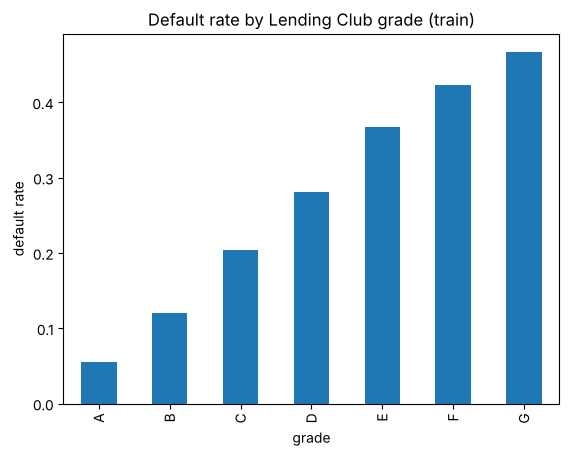

grade
A    0.056
B    0.120
C    0.204
D    0.281
E    0.368
F    0.423
G    0.467
Name: target, dtype: float64

In [ ]:
train = df[df["issue_d"] < "2016-01-01"]   # refresh train after the changes above

rate_by_grade = train.groupby("grade")["target"].mean()
rate_by_grade.plot(kind="bar", title="Default rate by Lending Club grade (train)")
plt.ylabel("default rate")
plt.show()
rate_by_grade.round(3)

**Observation:** the default rate rises steadily from grade A to grade G. Lending Club's
own grade is already a good risk model — this is the **baseline our model must beat**.

In [ ]:
print(train.groupby("term")["target"].mean().round(3), "\n")
print(train.groupby("home_ownership")["target"].mean().round(3), "\n")
print(train.groupby("purpose")["target"].mean().sort_values().round(3))

term
36    0.139
60    0.319
Name: target, dtype: float64 

home_ownership
MORTGAGE    0.163
OTHER       0.177
OWN         0.190
RENT        0.209
Name: target, dtype: float64 

purpose
wedding               0.121
car                   0.134
credit_card           0.155
major_purchase        0.162
home_improvement      0.165
vacation              0.172
educational           0.172
medical               0.194
other                 0.195
debt_consolidation    0.197
house                 0.208
moving                0.212
renewable_energy      0.219
small_business        0.270
Name: target, dtype: float64


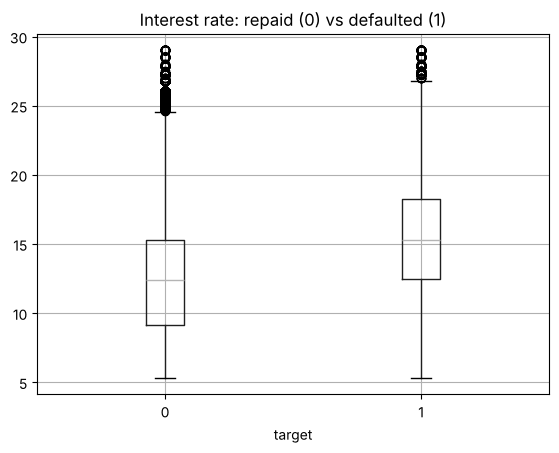

,int_rate,fico_range_low,dti,annual_inc
target,,,,
0,12.39,690.0,17.03,65000.0
1,15.31,680.0,19.62,60000.0


In [ ]:
train.boxplot(column="int_rate", by="target")
plt.title("Interest rate: repaid (0) vs defaulted (1)")
plt.suptitle("")
plt.show()

train.groupby("target")[["int_rate", "fico_range_low", "dti", "annual_inc"]].median()

**Observation:**
- 60-month loans default much more than 36-month loans.
- Renters default more than people with a mortgage.
- `small_business` is the riskiest purpose, `car` among the safest.
- Defaulted loans have a higher interest rate, a lower FICO score and a higher DTI.

In [ ]:
num_cols = ["loan_amnt", "installment", "int_rate", "annual_inc", "dti", "fico_range_low", "target"]
train[num_cols].corr().round(2)

,loan_amnt,installment,int_rate,annual_inc,dti,fico_range_low,target
loan_amnt,1.00,0.95,0.14,0.42,0.03,0.12,0.06
installment,0.95,1.00,0.13,0.41,0.03,0.07,0.03
int_rate,0.14,0.13,1.00,-0.09,0.16,-0.43,0.25
annual_inc,0.42,0.41,-0.09,1.00,-0.22,0.10,-0.05
dti,0.03,0.03,0.16,-0.22,1.00,-0.09,0.11
fico_range_low,0.12,0.07,-0.43,0.10,-0.09,1.00,-0.13
target,0.06,0.03,0.25,-0.05,0.11,-0.13,1.00


**Observation:** `loan_amnt` and `installment` are almost perfectly correlated (the
instalment is computed from the amount, rate and term). For a linear model this
collinearity makes the coefficients unstable.

### Step 13 — Why we did not use the extra bureau columns

The file has ~49 extra credit-bureau columns (`bc_util`, `num_*`, `il_util`, ...). When
do they start to have values?

In [ ]:
for col in ["bc_util", "il_util"]:
    first = df.loc[df[col].notna(), "issue_d"].min()
    print(col, "first non-empty month:", first.strftime("%Y-%m"),
          "| missing in train:", round(train[col].isna().mean(), 3))

bc_util first non-empty month: 2012-03 | missing in train: 0.067
il_util first non-empty month: 2015-12 | missing in train: 0.98


In [ ]:
train.groupby(train["issue_d"].dt.year)[["bc_util", "il_util"]].apply(lambda g: g.isna().mean()).round(2)

,bc_util,il_util
issue_d,,
2007,1.00,1.00
2008,1.00,1.00
2009,1.00,1.00
2010,1.00,1.00
2011,1.00,1.00
2012,0.15,1.00
2013,0.01,1.00
2014,0.01,1.00
2015,0.01,0.96


**Observation:**
- `bc_util` (and most of this group) is empty for every loan before 2012, then almost always
  present. In the training rows it is missing only for the early years.
- `il_util` (and 13 similar columns) only starts in **December 2015** — it is missing for
  almost all training rows, so it cannot be used at all.

We kept the feature set to columns available across the whole 2007–2015 training window.
Adding the 2012+ bureau columns (with training restricted to 2012+) is a possible
extension.

## Summary — first observations

| # | What I found | What I decided |
|---|---|---|
| 1 | 151 columns, many describe events **after** the loan | Load only application-time columns; remove leakage |
| 2 | `loan_status` has 9 values, some loans are unfinished | Keep finished loans only → about 1.35M rows |
| 3 | About 20% default | Do not use accuracy; use PR-AUC / ROC-AUC |
| 4 | Recent loans are mostly unfinished (right-censoring) | Remember the test default rate is biased |
| 5 | Numbers and dates stored as text | Convert them |
| 6 | Very few impossible values | Count, then drop (about 0.03%) |
| 7 | `ANY` / `NONE` / `OTHER` mean the same | Merge into `OTHER` |
| 8 | Extreme incomes and DTI | Clip at fixed limits, not percentiles |
| 9 | Loans arrive over time | Split by date (train < 2016) **before** exploring |
| 10 | Some blanks carry meaning | Add `_was_missing` flags |
| 11 | Default rises with grade A → G | Lending Club grade is the baseline to beat |
| 12 | Extra bureau columns start in 2012 or late 2015 | Not used in the current scope |